## Machine Learning: Modelo Supervisado No 5. El Modelo Random Forest

### Andrés Eduardo Rangel Jiménez


- Economista `(Universidad del Valle, Colombia)`

- MSc en Econometria `(Universidad Torcuato Di Tella, Argentina)`

- PhD en Dirección de Empresas `(Universidad de Valencia, España)`

In [2]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import  RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, RocCurveDisplay
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve)
import pickle
import warnings

#### Cargamos base de datos

```
Los registros de viajes de los taxis amarillos y verdes incluyen campos que capturan las fechas y horas de recogida y llegada, los lugares de recogida y llegada, las distancias recorridas, las tarifas detalladas, los tipos de tarifa, los métodos de pago y el número de pasajeros reportado por el conductor.



In [4]:
datos = pd.read_parquet('yellow_tripdata_2024-01.parquet')
datos.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


#### Objetivo. 

Deseamos construir un modelo que prediga si el cliente va a pagar con tarjeta de credito o en efectivo.

### 0. Construyendo la variable dependiente
```
Para modelar la probabilidad de pagar con tarjeta, filtramos  solo 1 y 2 (recomendada)

In [6]:
# Filtrar solo pagos con tarjeta (1) y efectivo (2)
datos = datos[datos["payment_type"].isin([1, 2])].copy()

# Crear variable objetivo binaria
datos["card"] = (datos["payment_type"] == 1).astype(int)

print(datos['card'].value_counts(normalize=True))

card
1    0.840771
0    0.159229
Name: proportion, dtype: float64


### 1. Feature engineering determinístico 
```

La regla que define qué va en el feature engineering determinístico
Una transformación es determinística cuando depende solo de los datos de entrada de una fila, no de estadísticos calculados a partir del target

Crear hour, trip_duration_min, etc., que no dependen del target → sobre datos completos.

In [8]:
# Asegurar datetime parseado (por si acaso)
datos['tpep_pickup_datetime']  = pd.to_datetime(datos['tpep_pickup_datetime'])
datos['tpep_dropoff_datetime'] = pd.to_datetime(datos['tpep_dropoff_datetime'])

# --- Variables temporales básicas (¡estas faltaban!) ---
datos['hour']      = datos['tpep_pickup_datetime'].dt.hour
datos['dayofweek'] = datos['tpep_pickup_datetime'].dt.dayofweek

# --- Duración del viaje en minutos ---
datos['trip_duration_min'] = (
    (datos['tpep_dropoff_datetime'] - datos['tpep_pickup_datetime'])
    .dt.total_seconds() / 60
)

# --- Velocidad promedio en millas/hora (con protección contra división por cero) ---
datos['avg_speed_mph'] = datos['trip_distance'] / (
    datos['trip_duration_min'] / 60
).replace(0, np.nan)

# --- Tarifa por milla ---
datos['fare_per_mile'] = datos['fare_amount'] / datos['trip_distance'].replace(0, np.nan)

# --- Features binarias temporales (ahora sí 'hour' y 'dayofweek' existen) ---
datos['is_weekend']   = datos['dayofweek'].isin([5, 6]).astype(int)
datos['is_rush_hour'] = datos['hour'].isin([7, 8, 9, 17, 18, 19]).astype(int)
datos['is_night']     = datos['hour'].isin([22, 23, 0, 1, 2, 3]).astype(int)

# ---  Dictotomicas aeropuesto ---
datos["airport"] = (datos["Airport_fee"] > 0).astype(int)


# --- Limpieza de valores imposibles ---
datos = datos[
    datos['trip_duration_min'].between(1, 180) &
    datos['avg_speed_mph'].between(1, 80)
].reset_index(drop=True)

# --- Rellenar NaN residuales con mediana ---
for col in ['avg_speed_mph', 'fare_per_mile']:
    datos[col] = datos[col].fillna(datos[col].median())

print(f"Filas después de FE: {len(datos):,}")
print("Nuevas columnas creadas:", [
    'hour', 'dayofweek', 'trip_duration_min', 'avg_speed_mph', 'fare_per_mile',
    'is_weekend', 'is_rush_hour', 'is_night'
])

Filas después de FE: 2,718,664
Nuevas columnas creadas: ['hour', 'dayofweek', 'trip_duration_min', 'avg_speed_mph', 'fare_per_mile', 'is_weekend', 'is_rush_hour', 'is_night']


In [125]:
cols_necesarias = [
    'fare_amount', 'trip_distance', 'hour', 'passenger_count', 'dayofweek',
    'trip_duration_min', 'avg_speed_mph', 'fare_per_mile',
    'is_weekend', 'is_rush_hour', 'is_night',
    'card',  # para el split estratificado
]

faltantes = [c for c in cols_necesarias if c not in datos.columns]
if faltantes:
    print("FALTAN estas columnas:", faltantes)
else:
    print("✓ Todas las columnas existen, puedes continuar al Paso 2")

✓ Todas las columnas existen, puedes continuar al Paso 2


### Paso 2: Definiendo features
```
Los features deterministicos definidos antes de muestrear

Una feature determinística da exactamente el mismo resultado fila por fila sin importar dónde la calcules en el pipeline. Matemáticamente es idéntico hacer:

datos → FE → muestra → split
datos → muestra → FE → split
datos → muestra → split → FE (sobre X_train y X_test por separado)

Sin embargo por razones practicas hay una  razon concreta por la que el lugar correcto es siempre antes de la muestra:

Si quieres estratificar o filtrar usando la feature nueva, tiene que existir.

Si decides que tu muestra debe estratificarse no solo por card sino también por is_airport_trip, o que quieres excluir viajes con trip_duration_min < 1, necesitas la columna creada antes del muestreo.

Los pipelines se leen mejor cuando están organizados por etapas.
El orden canónico en ML es:

1. Carga de datos
2. Limpieza + FE determinístico       ← "preparación de los datos"
3. Muestreo / split                   ← "separar train y test"
4. FE dependiente de y (target enc.)  ← "transformaciones que aprenden de y_train"
5. Escalado (si aplica)               ← ídem
6. Entrenamiento                      ← modelo
7. Evaluación                         ← métricas


In [27]:
features = [
    'fare_amount', 'trip_distance', 'hour', 'passenger_count', 'dayofweek',
    'trip_duration_min', 'avg_speed_mph', 'fare_per_mile',
    'is_weekend', 'is_rush_hour', 'is_night',
    'PULocationID', 'DOLocationID',  
]

### Paso 3:  Muestrea primero 
```
Al muestrear primero reduces el volumen antes de cualquier operación costosa.


In [30]:
#Con un desbalance de 84/16 la versión estratificada es la correcta:
datos_muestra = (
    datos.groupby('card', group_keys=False)
         .sample(frac=0.2, random_state=42)
        .reset_index(drop=True)
)
print(f"Muestra: {len(datos_muestra):,} filas")

Muestra: 543,732 filas


### Paso 4. Split:

In [33]:
X = datos_muestra[features]
y = datos_muestra['card']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### Paso 5 Target encoding

In [36]:
# PULocationID — construimos el mapa SOLO con train
pu_map = X_train.join(y_train).groupby("PULocationID")["card"].mean()
X_train["PULocationID_enc"] = X_train["PULocationID"].map(pu_map)
X_test["PULocationID_enc"]  = X_test["PULocationID"].map(pu_map).fillna(pu_map.mean())

# DOLocationID — idem
do_map = X_train.join(y_train).groupby("DOLocationID")["card"].mean()
X_train["DOLocationID_enc"] = X_train["DOLocationID"].map(do_map)
X_test["DOLocationID_enc"]  = X_test["DOLocationID"].map(do_map).fillna(do_map.mean())

# Eliminar columnas originales de ID (ya no se usan como numéricas)
X_train = X_train.drop(columns=["PULocationID", "DOLocationID"])
X_test  = X_test.drop(columns=["PULocationID", "DOLocationID"])

print("Shape train:", X_train.shape, "Shape test:", X_test.shape)
print("Columnas finales:", X_train.columns.tolist())

Shape train: (434985, 13) Shape test: (108747, 13)
Columnas finales: ['fare_amount', 'trip_distance', 'hour', 'passenger_count', 'dayofweek', 'trip_duration_min', 'avg_speed_mph', 'fare_per_mile', 'is_weekend', 'is_rush_hour', 'is_night', 'PULocationID_enc', 'DOLocationID_enc']


### Pasos 6 y 7 — Entrenar el RF. Modelo Base y evaluacion

Al usar class_weight='balanced' puedo prescindir del  BALANCEO 70/30 (solo sobre train) pues ya vimos que en CART ambas maneras de tratar el balanceo es similar.

In [39]:
rf_base = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    n_jobs=-1,
    random_state=42,
)
rf_base.fit(X_train, y_train)

y_pred_rf_base  = rf_base.predict(X_test)
y_proba_rf_base = rf_base.predict_proba(X_test)[:, 1]

print("Classification report — RF base:")
print(classification_report(y_test, y_pred_rf_base,
                            target_names=['Efectivo', 'Tarjeta']))
print(f"ROC-AUC RF base: {roc_auc_score(y_test, y_proba_rf_base):.4f}")

Classification report — RF base:
              precision    recall  f1-score   support

    Efectivo       0.71      0.04      0.08     17042
     Tarjeta       0.85      1.00      0.92     91705

    accuracy                           0.85    108747
   macro avg       0.78      0.52      0.50    108747
weighted avg       0.83      0.85      0.79    108747

ROC-AUC RF base: 0.6540


```
De entrada el modelo base sin el GridSearch ya supera al modelo CART con GridSearch

No es espectacular, pero confirma que el RF ordena mejor las probabilidades. La señal está ahí.

Con 84/16 de desbalance, la regla óptima para el RF a nivel de árbol es casi siempre "predice la mayoría". El ROC-AUC ignora el umbral, por eso ahí sí ves mejora; pero las métricas a threshold=0.5 están rotas.


### Paso 7.1. Importancias 

In [51]:
importancias = (
    pd.DataFrame({
        'feature':    X_train.columns,
        'importance': rf_base.feature_importances_,
    })
    .sort_values('importance', ascending=False)
    .reset_index(drop=True)
)
print("Importancia de variables (RF con FE + target encoding):")
print(importancias.to_string(index=False))
print(f"\nTotal features: {len(importancias)}")
print(f"Suma de importancias: {importancias['importance'].sum():.4f}")

Importancia de variables (RF con FE + target encoding):
          feature  importance
 DOLocationID_enc    0.283321
    fare_per_mile    0.155714
      fare_amount    0.137970
 PULocationID_enc    0.134573
    trip_distance    0.067061
    avg_speed_mph    0.060443
trip_duration_min    0.049693
             hour    0.049033
  passenger_count    0.024155
        dayofweek    0.016191
     is_rush_hour    0.009251
         is_night    0.006584
       is_weekend    0.006011

Total features: 13
Suma de importancias: 1.0000


### GridSearch

In [53]:
# === Espacio de búsqueda (ahora incluye class_weight) ===
rf_param_dist = {
    'n_estimators':       [200, 300, 500],
    'max_depth':          [8, 12, 16, 20, None],
    'min_samples_split':  [10, 50, 100],
    'min_samples_leaf':   [5, 20, 50],
    'max_features':       ['sqrt', 'log2', 0.5],
    'criterion':          ['gini', 'entropy'],
    'class_weight':       ['balanced', 'balanced_subsample', None],
}

# === Búsqueda aleatoria ===
random_search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(       # <-- ya NO fijamos class_weight aquí
        random_state=42,
        n_jobs=-1,
    ),
    param_distributions=rf_param_dist,
    n_iter=20,           # 20 combinaciones aleatorias (sube a 40 si tienes tiempo)
    scoring='roc_auc',   # optimizar ranking, no predicción a threshold 0.5
    cv=3,                # 3 folds en lugar de 5 para ir más rápido
    n_jobs=-1,
    random_state=42,
    verbose=2,
)

random_search_rf.fit(X_train, y_train)

print("Mejores hiperparámetros RF:", random_search_rf.best_params_)
print(f"Mejor ROC-AUC CV: {random_search_rf.best_score_:.4f}")

# === Guardar el mejor modelo y generar predicciones sobre test ===
rf_final = random_search_rf.best_estimator_

y_pred_rf  = rf_final.predict(X_test)
y_proba_rf = rf_final.predict_proba(X_test)[:, 1]

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=8, max_features=0.5, min_samples_leaf=50, min_samples_split=100, n_estimators=300; total time= 2.5min
[CV] END class_weight=None, criterion=gini, max_depth=8, max_features=sqrt, min_samples_leaf=50, min_samples_split=10, n_estimators=200; total time=  47.5s
[CV] END class_weight=None, criterion=entropy, max_depth=12, max_features=0.5, min_samples_leaf=20, min_samples_split=10, n_estimators=200; total time= 2.1min
[CV] END class_weight=balanced, criterion=entropy, max_depth=8, max_features=0.5, min_samples_leaf=5, min_samples_split=100, n_estimators=300; total time= 2.2min
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=20, max_features=sqrt, min_samples_leaf=50, min_samples_split=100, n_estimators=200; total time= 1.6min
[CV] END class_weight=balanced, criterion=gini, max_depth=12, max_features=log2, min_samples_leaf=50, min_samples_

```
Los mejores hiperparámetros fueron:

n_estimators: 200, min_samples_split: 10, min_samples_leaf: 20,
max_features: 0.5, max_depth: 12, criterion: 'entropy',
class_weight: None
ROC-AUC CV: 0.6454

### Modelo final y  predicciones

EVALUACIÓN COMPLETA — MODELO RF FINAL

--- Classification Report ---
              precision    recall  f1-score   support

    Efectivo     0.7159    0.0410    0.0775     17042
     Tarjeta     0.8483    0.9970    0.9167     91705

    accuracy                         0.8472    108747
   macro avg     0.7821    0.5190    0.4971    108747
weighted avg     0.8276    0.8472    0.7852    108747

ROC-AUC test:  0.6541
ROC-AUC CV:    0.6552
PR-AUC (Tarjeta, clase 1): 0.9020
PR-AUC (Efectivo, clase 0): 0.3039

--- Tabla detallada de métricas ---
                     Métrica  Valor
                    Accuracy 0.8472
           Balanced Accuracy 0.5190
Precision Efectivo (clase 0) 0.7159
   Recall Efectivo (clase 0) 0.0410
       F1 Efectivo (clase 0) 0.0775
 Precision Tarjeta (clase 1) 0.8483
    Recall Tarjeta (clase 1) 0.9970
        F1 Tarjeta (clase 1) 0.9167
                    F1 Macro 0.4971
                 F1 Weighted 0.7852
                     ROC-AUC 0.6541
            PR-AUC (Ta

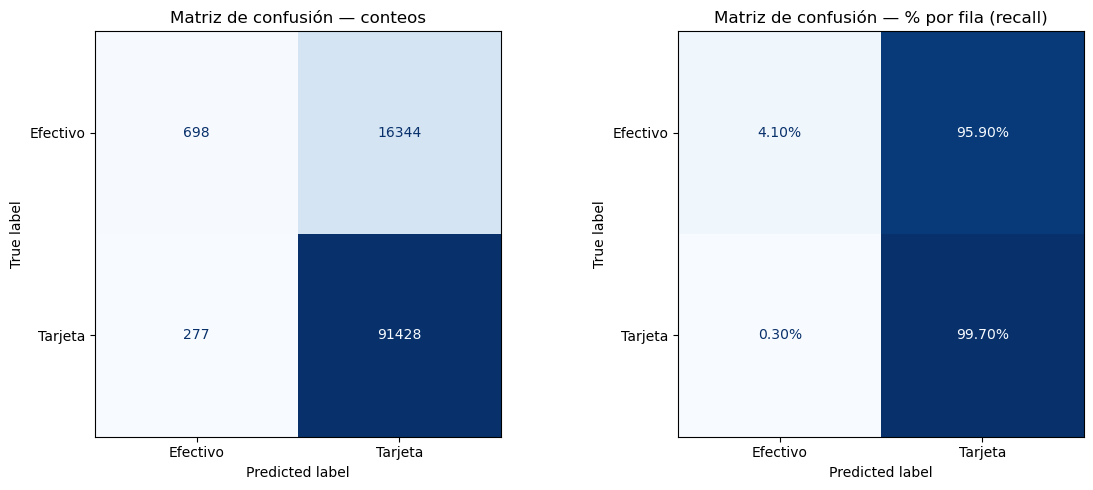


--- Desglose de la matriz de confusión ---
True Negatives  (Efectivo → Efectivo):     698
False Positives (Efectivo → Tarjeta):   16,344
False Negatives (Tarjeta → Efectivo):      277
True Positives  (Tarjeta → Tarjeta):    91,428


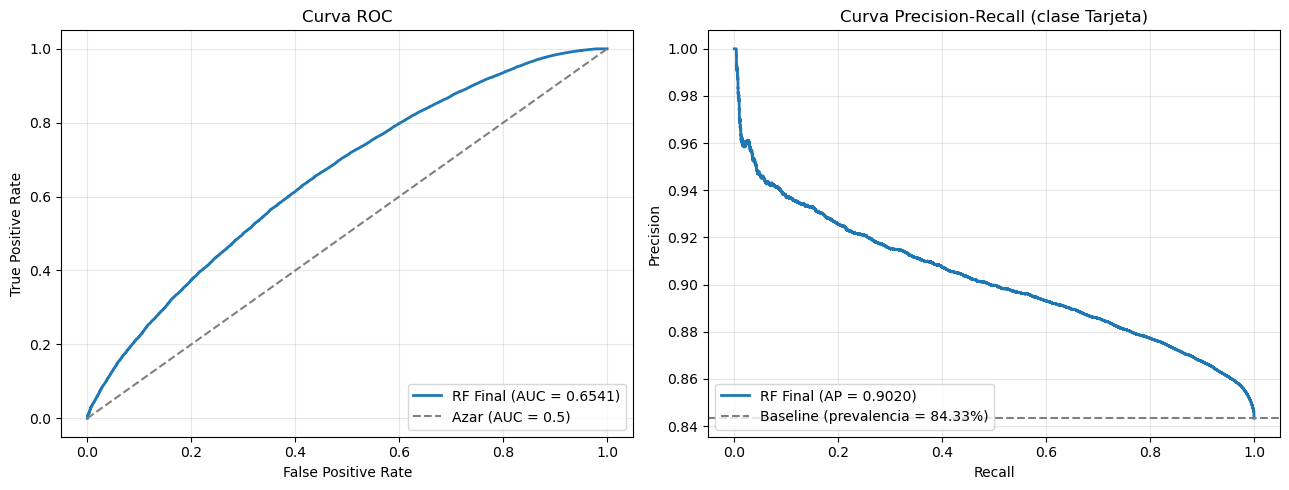


--- Importancia de variables ---
          feature  importance
 DOLocationID_enc    0.267588
 PULocationID_enc    0.140242
    fare_per_mile    0.137065
      fare_amount    0.123733
    trip_distance    0.071860
    avg_speed_mph    0.069483
             hour    0.060017
trip_duration_min    0.057512
  passenger_count    0.026285
        dayofweek    0.019696
     is_rush_hour    0.010462
         is_night    0.008579
       is_weekend    0.007478


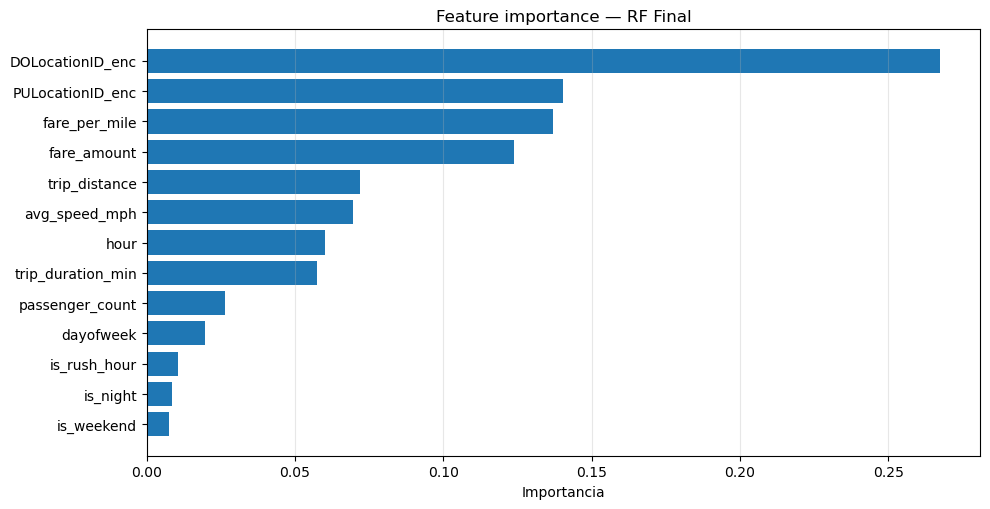


--- Hiperparámetros del modelo final ---
          n_estimators: 500
     min_samples_split: 10
      min_samples_leaf: 5
          max_features: log2
             max_depth: 12
             criterion: entropy
          class_weight: None


In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve,
    matthews_corrcoef, cohen_kappa_score, balanced_accuracy_score,
    log_loss, brier_score_loss,
)

# ============================================================
# 1) CLASSIFICATION REPORT Y ROC-AUC
# ============================================================
print("=" * 70)
print("EVALUACIÓN COMPLETA — MODELO RF FINAL")
print("=" * 70)
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_rf,
                            target_names=['Efectivo', 'Tarjeta'], digits=4))

print(f"ROC-AUC test:  {roc_auc_score(y_test, y_proba_rf):.4f}")
print(f"ROC-AUC CV:    {random_search_rf.best_score_:.4f}")
print(f"PR-AUC (Tarjeta, clase 1): {average_precision_score(y_test, y_proba_rf):.4f}")
print(f"PR-AUC (Efectivo, clase 0): {average_precision_score(1 - y_test, 1 - y_proba_rf):.4f}")

# ============================================================
# 2) TABLA DETALLADA DE MÉTRICAS
# ============================================================
metricas_detalladas = pd.DataFrame({
    'Métrica': [
        'Accuracy',
        'Balanced Accuracy',
        'Precision Efectivo (clase 0)',
        'Recall Efectivo (clase 0)',
        'F1 Efectivo (clase 0)',
        'Precision Tarjeta (clase 1)',
        'Recall Tarjeta (clase 1)',
        'F1 Tarjeta (clase 1)',
        'F1 Macro',
        'F1 Weighted',
        'ROC-AUC',
        'PR-AUC (Tarjeta)',
        'Matthews Corrcoef (MCC)',
        'Cohen Kappa',
        'Log Loss',
        'Brier Score',
    ],
    'Valor': [
        accuracy_score(y_test, y_pred_rf),
        balanced_accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, pos_label=0),
        recall_score(y_test, y_pred_rf, pos_label=0),
        f1_score(y_test, y_pred_rf, pos_label=0),
        precision_score(y_test, y_pred_rf, pos_label=1),
        recall_score(y_test, y_pred_rf, pos_label=1),
        f1_score(y_test, y_pred_rf, pos_label=1),
        f1_score(y_test, y_pred_rf, average='macro'),
        f1_score(y_test, y_pred_rf, average='weighted'),
        roc_auc_score(y_test, y_proba_rf),
        average_precision_score(y_test, y_proba_rf),
        matthews_corrcoef(y_test, y_pred_rf),
        cohen_kappa_score(y_test, y_pred_rf),
        log_loss(y_test, y_proba_rf),
        brier_score_loss(y_test, y_proba_rf),
    ],
}).round(4)

print("\n--- Tabla detallada de métricas ---")
print(metricas_detalladas.to_string(index=False))

# ============================================================
# 3) MATRIZ DE CONFUSIÓN (conteos y porcentajes)
# ============================================================
cm = confusion_matrix(y_test, y_pred_rf)
cm_pct = confusion_matrix(y_test, y_pred_rf, normalize='true')  # % por fila (recall)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(cm, display_labels=['Efectivo', 'Tarjeta']).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d'
)
axes[0].set_title("Matriz de confusión — conteos")

ConfusionMatrixDisplay(cm_pct, display_labels=['Efectivo', 'Tarjeta']).plot(
    ax=axes[1], cmap='Blues', colorbar=False, values_format='.2%'
)
axes[1].set_title("Matriz de confusión — % por fila (recall)")

plt.tight_layout()
plt.show()

# Desglose explícito
tn, fp, fn, tp = cm.ravel()
print("\n--- Desglose de la matriz de confusión ---")
print(f"True Negatives  (Efectivo → Efectivo): {tn:>7,}")
print(f"False Positives (Efectivo → Tarjeta):  {fp:>7,}")
print(f"False Negatives (Tarjeta → Efectivo):  {fn:>7,}")
print(f"True Positives  (Tarjeta → Tarjeta):   {tp:>7,}")

# ============================================================
# 4) CURVAS ROC Y PRECISION-RECALL
# ============================================================
fpr, tpr, _ = roc_curve(y_test, y_proba_rf)
prec, rec, _ = precision_recall_curve(y_test, y_proba_rf)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"RF Final (AUC = {roc_auc_score(y_test, y_proba_rf):.4f})",
             linewidth=2)
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Azar (AUC = 0.5)')
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Curva ROC")
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

axes[1].plot(rec, prec,
             label=f"RF Final (AP = {average_precision_score(y_test, y_proba_rf):.4f})",
             linewidth=2)
axes[1].axhline(y_test.mean(), color='gray', linestyle='--',
                label=f'Baseline (prevalencia = {y_test.mean():.2%})')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Curva Precision-Recall (clase Tarjeta)")
axes[1].legend(loc='lower left')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 5) IMPORTANCIA DE VARIABLES
# ============================================================
importancias = (
    pd.DataFrame({
        'feature':    X_train.columns,
        'importance': rf_final.feature_importances_,
    })
    .sort_values('importance', ascending=False)
    .reset_index(drop=True)
)

print("\n--- Importancia de variables ---")
print(importancias.to_string(index=False))

# Gráfica horizontal de importancias
fig, ax = plt.subplots(figsize=(10, max(4, 0.4 * len(importancias))))
ax.barh(importancias['feature'][::-1], importancias['importance'][::-1])
ax.set_xlabel("Importancia")
ax.set_title("Feature importance — RF Final")
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 6) HIPERPARÁMETROS DEL MEJOR MODELO (para documentación)
# ============================================================
print("\n--- Hiperparámetros del modelo final ---")
for param, valor in random_search_rf.best_params_.items():
    print(f"  {param:>20}: {valor}")

### Conclusion

```
Si el AUC se queda pegado en ~0.65, agregas las features de ingeniería (duración, velocidad, fare_per_mile, is_weekend, is_rush_hour) que te pasé antes — suelen aportar 3–5 puntos de AUC.
0.6431 → 0.6445. Esto es crucial: class_weight no cambia el ranking que produce el modelo (la capacidad de ordenar probabilidades), solo cambia dónde se corta para decidir clase. Al quedarse casi idéntico, te dice una cosa muy concreta:

El techo de información que tienen los  features actuales es AUC ≈ 0.64–0.65.

Esto significa que por más que se tunees hiperparámetros con RandomizedSearchCV, se va a obtener a lo sumo 0.01–0.02 más. El modelo no tiene más información para extraer. Es el techo de las features, no del algoritmo.

Recomendación: feature engineering PRIMERO, luego RandomizedSearch
Orden óptimo:

Ahora: agregar las features de duración, velocidad, fare_per_mile, is_weekend, is_rush_hour. Esto ataca la fuente del problema (poca información) en vez de la síntoma (modelo desafinado).
Reentrenar el RF balanced con las features nuevas para ver el nuevo techo de AUC. Con esas 5–6 features extra, es normal pasar de 0.64 a 0.72–0.78.
Recién ahí: correr RandomizedSearchCV, porque ya valdrá la pena tunear (subir de 0.75 a 0.78 sí es notable, subir de 0.64 a 0.66 no).

Hacerlo al revés (tunear primero y luego enriquecer features) es como lijar un mueble antes de cortar las patas al tamaño correcto: desperdicias esfuerzo.

### Ejercicio 2



#### Importación de la base

In [59]:
datos=pd.read_csv("Social_Network_Ads.csv")

In [116]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


#### Preprocesamiento

In [61]:
print("\n" + "=" * 70)
print("2. PREPROCESAMIENTO")
print("=" * 70)
 
# Eliminamos User ID (no aporta valor predictivo)
df = datos.drop(columns=["User ID"])
 
# Codificamos Gender (Male/Female) a numérico
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])  # Female=0, Male=1 (o al revés)
 
# Definimos features (X) y target (y)
X = df.drop(columns=["Purchased"])
y = df["Purchased"]
 
print(f"Forma de X: {X.shape}")
print(f"Forma de y: {y.shape}")


2. PREPROCESAMIENTO
Forma de X: (400, 3)
Forma de y: (400,)


#### Particion en train y test

In [67]:
SEED = 42
np.random.seed(SEED)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=SEED,
    stratify=y
)
 
print(f"\nTrain: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Proporción clases en train:\n{y_train.value_counts(normalize=True)}")
print(f"Proporción clases en test:\n{y_test.value_counts(normalize=True)}")


Train: (300, 3)  |  Test: (100, 3)
Proporción clases en train:
Purchased
0    0.643333
1    0.356667
Name: proportion, dtype: float64
Proporción clases en test:
Purchased
0    0.64
1    0.36
Name: proportion, dtype: float64


#### Estandarizamos

In [125]:
# Escalamos (Random Forest no lo requiere, pero es útil si comparas con otros modelos)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Modelo base

In [71]:
print("\n" + "=" * 70)
print("3. MODELO BASE")
print("=" * 70)
 
modelo_base = RandomForestClassifier(random_state=SEED, n_jobs=-1)
modelo_base.fit(X_train, y_train)
 
# Predicciones
y_pred_base = modelo_base.predict(X_test)
y_proba_base = modelo_base.predict_proba(X_test)[:, 1]

# Métricas del modelo base
metricas_base = {
    "Accuracy":  accuracy_score(y_test, y_pred_base),
    "Precision": precision_score(y_test, y_pred_base),
    "Recall":    recall_score(y_test, y_pred_base),
    "F1-score":  f1_score(y_test, y_pred_base),
    "ROC-AUC":   roc_auc_score(y_test, y_proba_base),
}
 
print("Métricas del Modelo Base:")
for k, v in metricas_base.items():
    print(f"  {k:<10}: {v:.4f}")
 
print("\nReporte de clasificación (Base):")
print(classification_report(y_test, y_pred_base))


3. MODELO BASE
Métricas del Modelo Base:
  Accuracy  : 0.9000
  Precision : 0.8421
  Recall    : 0.8889
  F1-score  : 0.8649
  ROC-AUC   : 0.9210

Reporte de clasificación (Base):
              precision    recall  f1-score   support

           0       0.94      0.91      0.92        64
           1       0.84      0.89      0.86        36

    accuracy                           0.90       100
   macro avg       0.89      0.90      0.89       100
weighted avg       0.90      0.90      0.90       100



#### Trabajando con Pipeline: Una nota metodologíca
```

Un Pipeline (en sklearn) es un objeto que encadena varios pasos de preprocesamiento y un modelo final en una sola unidad. En lugar de aplicar el escalado, la codificación y el modelo por separado, los "empaquetas" y los ejecutas como si fueran un solo estimador: cuando haces .fit() ejecuta todos los pasos en orden sobre el train, y cuando haces .predict() aplica los mismos pasos (ya aprendidos) sobre nuevos datos.

¿Por qué es importante?

- Evita data leakage (fuga de información): si escalas ANTES de hacer el split o dentro de cross-validation manualmente, el modelo "ve" información del test. El 
- Pipeline garantiza que el StandardScaler se ajuste solo con el train en cada fold.
- Código más limpio y reproducible: un solo objeto para entrenar, predecir y guardar.
- Se integra perfecto con GridSearchCV: puedes tunear hiperparámetros del preprocesamiento Y del modelo a la vez.
- Garantiza el mismo tratamiento en producción: nuevos datos pasan automáticamente por los mismos pasos.

Otra forma de verlo: es como una línea de ensamblaje en una fábrica: pieza entra → se limpia → se pinta → se arma → sale producto final. Cambiar el orden o saltarse un paso rompe el producto.

#### Código: Modelo Base con Pipeline (escalado + Random Forest)

In [77]:
# 1. Definimos el pipeline: primero escala, luego entrena el Random Forest
pipeline_base = Pipeline(steps=[
    ("scaler", StandardScaler()),                              # Paso 1: estandarización
    ("rf",     RandomForestClassifier(random_state=42, n_jobs=-1))  # Paso 2: modelo
])

In [81]:
# 2. Entrenamos TODO el pipeline con una sola línea
pipeline_base.fit(X_train, y_train)

,steps,"[('scaler', ...), ('rf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2


In [136]:
# 3. Predecimos (aplica scaler.transform y luego rf.predict automáticamente)
y_pred_base = pipeline_base.predict(X_test)
y_proba_base = pipeline_base.predict_proba(X_test)[:, 1]

#### Nota sobre la diferencia entre .predict y .predict_proba
```
Nota:

predict() → devuelve la clase final (0 o 1). Es la decisión ya tomada por el modelo. 
Para cada fila del test, te dice: "esta persona compra" o "no compra". Tipo: enteros. Solo valores de las clases (en este caso 0 y 1).
array([0, 1, 0, 0, 1, 1, 0, ...])



predict_proba() → devuelve la probabilidad de cada clase. 
Para cada fila te da dos números (uno por clase) que suman 1

 array([[0.92, 0.08],   <- 92% no compra, 8% compra
        [0.15, 0.85],   <- 15% no compra, 85% compra
        [0.70, 0.30],
        ...])

Con [:, 1] te quedas solo con la columna de la clase positiva (probabilidad de comprar):
y_proba_base = pipeline_base.predict_proba(X_test)[:, 1]
# array([0.08, 0.85, 0.30, ...])


La relación entre ambas
Por defecto, predict() aplica un umbral de 0.5 a predict_proba():

si  predict_proba >= 0.5  →  predict = 1
si  predict_proba <  0.5  →  predict = 0

Es decir, predict es predict_proba con una decisión binaria aplicada encima.

¿Por qué necesitas las dos?

+---------------------------------------------+----------------------------+
| Métrica                                     | Qué usa                    |
+---------------------------------------------+----------------------------+
| Accuracy, Precision, Recall, F1,            | y_pred (clases)            |
| Confusion Matrix                            |                            |
+---------------------------------------------+----------------------------+
| ROC-AUC, curva ROC, curva Precision-Recall  | y_proba (probabilidades)   |
+---------------------------------------------+----------------------------+


El ROC-AUC necesita probabilidades porque evalúa el modelo en todos los umbrales posibles, no solo en 0.5. Si solo le pasaras las clases ya decididas, perderías toda esa información de "qué tan seguro estaba el modelo".

Analogía:

Imagínate un jurado que evalúa si un estudiante pasa un examen:

predict_proba es cuando el jurado dice: "estoy 85% seguro de que pasa".
predict es cuando el jurado dice: "pasa" o "no pasa" (ya tomó la decisión final con un umbral).

Un estudiante con probabilidad 0.51 y otro con 0.99 reciben el mismo predict = 1, pero el modelo no está igual de seguro de los dos. Por eso para métricas como ROC-AUC usamos la probabilidad cruda: conserva esa información de confianza.

#### Bonus 1: cambiar el umbral
```
Como tu clase está desbalanceada (64/36), a veces conviene bajar el umbral para capturar más compradores (más recall). Aca esta el codigo:

y_proba = pipeline_base.predict_proba(X_test)[:, 1]
y_pred_custom = (y_proba >= 0.4).astype(int)   # umbral personalizado

Esto es imposible de hacer con predict() directamente, porque ya te devolvió la decisión. Esa es otra razón por la que vale la pena guardar ambas.

#### Nota sobre el pipeline
```
Eso es todo: una sola llamada a .fit() hace el scaler.fit_transform(X_train) + rf.fit(...) internamente, y .predict() hace scaler.transform(X_test) + rf.predict(...). Nunca tienes que acordarte de escalar manualmente el test set.

####  1. Usar el pipeline en GridSearchCV (Bonus 2)
```

Aquí se ve el poder real. Fíjate en la sintaxis nombre_del_paso__hiperparametro:

In [87]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "rf__n_estimators":  [100, 200, 300],
    "rf__max_depth":     [None, 5, 10, 20],
    "rf__min_samples_leaf": [1, 2, 4],
    "rf__class_weight":  [None, "balanced"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=pipeline_base,   # <-- le pasamos el pipeline completo
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)   # escala + entrena + valida, todo dentro de cada fold

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'rf__class_weight': [None, 'balanced'], 'rf__max_depth': [None, 5, ...], 'rf__min_samples_leaf': [1, 2, ...], 'rf__n_estimators': [100, 200, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [89]:
# Mejor combinación de hiperparámetros encontrada
print("Mejores parámetros:")
for k, v in grid.best_params_.items():
    print(f"  {k}: {v}")

# Mejor score (F1 en validación cruzada) durante la búsqueda
print(f"\nMejor F1 en CV: {grid.best_score_:.4f}")

# Tabla completa con TODOS los experimentos (una fila por combinación probada)
resultados_cv = pd.DataFrame(grid.cv_results_)
resultados_cv = resultados_cv.sort_values("rank_test_score")
print(resultados_cv[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(10))

Mejores parámetros:
  rf__class_weight: balanced
  rf__max_depth: None
  rf__min_samples_leaf: 4
  rf__n_estimators: 100

Mejor F1 en CV: 0.8865
                                               params  mean_test_score  \
71  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
70  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
42  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
43  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
44  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
52  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
53  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
60  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
51  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   
61  {'rf__class_weight': 'balanced', 'rf__max_dept...         0.886498   

    std_test_score  rank_test_score  
71

#### 2. Extraer el modelo final (ya es un pipeline entrenado)

In [93]:
# best_estimator_ es el Pipeline completo (scaler + rf) ya re-entrenado con TODO el train
modelo_final = grid.best_estimator_

print(modelo_final)


Pipeline(steps=[('scaler', StandardScaler()),
                ('rf',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_leaf=4, n_jobs=-1,
                                        random_state=42))])


#### 3. Evaluar el modelo final sobre el test set
Aquí llamas al pipeline directamente. Internamente aplica scaler.transform(X_test) y luego rf.predict(...):


In [97]:
y_pred_final  = modelo_final.predict(X_test)
y_proba_final = modelo_final.predict_proba(X_test)[:, 1]

metricas_final = {
    "Accuracy":  accuracy_score(y_test, y_pred_final),
    "Precision": precision_score(y_test, y_pred_final),
    "Recall":    recall_score(y_test, y_pred_final),
    "F1-score":  f1_score(y_test, y_pred_final),
    "ROC-AUC":   roc_auc_score(y_test, y_proba_final),
}

print("Métricas del Modelo Final en Test:")
for k, v in metricas_final.items():
    print(f"  {k:<10}: {v:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_final))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_final))

Métricas del Modelo Final en Test:
  Accuracy  : 0.9000
  Precision : 0.8421
  Recall    : 0.8889
  F1-score  : 0.8649
  ROC-AUC   : 0.9523

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.94      0.91      0.92        64
           1       0.84      0.89      0.86        36

    accuracy                           0.90       100
   macro avg       0.89      0.90      0.89       100
weighted avg       0.90      0.90      0.90       100

Matriz de confusión:
[[58  6]
 [ 4 32]]


### 4. Acceder a pasos específicos dentro del pipeline
```
Muy útil para sacar la importancia de variables del Random Forest, o los parámetros aprendidos por el scaler:


In [153]:
# Con .named_steps accedes a cada componente por su nombre
rf_final     = modelo_final.named_steps["rf"]
scaler_final = modelo_final.named_steps["scaler"]

# Importancia de variables (del RF de adentro)
importancias = pd.DataFrame({
    "Variable":    X.columns,
    "Importancia": rf_final.feature_importances_
}).sort_values("Importancia", ascending=False)

print(importancias)

# Media y desviación aprendidas por el scaler
print("\nMedia aprendida por el scaler:", scaler_final.mean_)
print("Desviación aprendida por el scaler:", scaler_final.scale_)

          Variable  Importancia
1              Age     0.542884
2  EstimatedSalary     0.450114
0           Gender     0.007002

Media aprendida por el scaler: [4.60000000e-01 3.71400000e+01 7.09033333e+04]
Desviación aprendida por el scaler: [4.98397432e-01 1.06091344e+01 3.51629633e+04]


Nota: También funciona con modelo_final["rf"] o modelo_final.steps[1][1], pero named_steps es el más legible.

#### 5. Visualizar: matriz de confusión y curva ROC

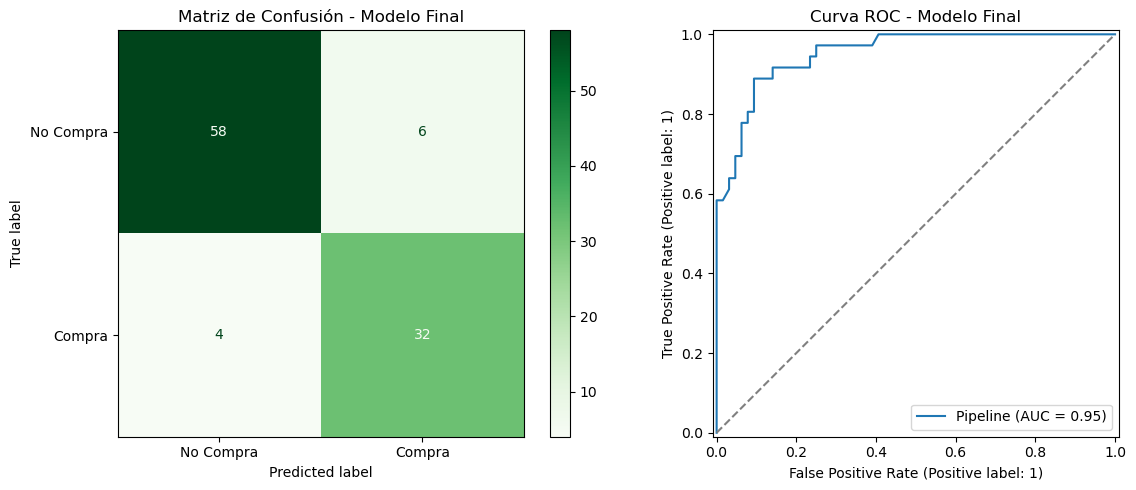

In [99]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de confusión
ConfusionMatrixDisplay.from_estimator(
    modelo_final, X_test, y_test,
    display_labels=["No Compra", "Compra"],
    cmap="Greens", ax=axes[0]
)
axes[0].set_title("Matriz de Confusión - Modelo Final")

# Curva ROC
RocCurveDisplay.from_estimator(modelo_final, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("Curva ROC - Modelo Final")

plt.tight_layout()
plt.show()

Nota:  cómo from_estimator acepta el pipeline directo: él se encarga de transformar X_test internamente. No tienes que escalarlo a mano.

#### 6. Guardar el modelo final (bonus para producción)
Como el pipeline incluye el escalado + el modelo, se guarda un solo archivo que ya contiene todo el preprocesamiento aprendido:

In [182]:
X_nuevos = pd.DataFrame([
    {"Gender": 0, "Age": 22, "EstimatedSalary": 25000},
    {"Gender": 1, "Age": 45, "EstimatedSalary": 90000},
    {"Gender": 1, "Age": 30, "EstimatedSalary": 55000},
    {"Gender": 0, "Age": 60, "EstimatedSalary": 120000},
])

modelo_cargado = joblib.load("modelo_final_rf.pkl")
resultados = X_nuevos.copy()
resultados["Prediccion"]      = modelo_cargado.predict(X_nuevos)
resultados["Prob_Compra"]     = modelo_cargado.predict_proba(X_nuevos)[:, 1].round(3)

print(resultados)

   Gender  Age  EstimatedSalary  Prediccion  Prob_Compra
0       0   22            25000           0        0.013
1       1   45            90000           1        0.900
2       1   30            55000           0        0.026
3       0   60           120000           1        0.932


In [180]:
import joblib

joblib.dump(modelo_final, "modelo_final_rf.pkl")

# Más tarde, para predecir sobre datos nuevos:
modelo_cargado = joblib.load("modelo_final_rf.pkl")
predicciones_nuevas = modelo_cargado.predict(X_nuevos)  # ya aplica el scaler por dentro

nota. Esto es otra ventaja grande del pipeline que vale la pena enseñarles: no tienes que guardar el scaler y el modelo por separado, ni recordar en qué orden aplicarlos.

```

¿Qué significa la extensión .pkl?
.pkl viene de "pickle", que es el módulo nativo de Python para serializar objetos. Serializar significa convertir un objeto de Python (que vive en memoria RAM) en una secuencia de bytes que se puede guardar en disco o enviar por red. Luego, al cargarlo, Python reconstruye el objeto exactamente como estaba.
En tu caso, el pipeline entrenado (scaler + Random Forest con todos sus árboles ya aprendidos) es un objeto Python complejo que ocupa mucha RAM. joblib.dump() lo convierte a bytes y los escribe en modelo_final_rf.pkl. Cuando haces joblib.load(), Python lee esos bytes y reconstruye el pipeline listo para predecir.
No es un formato de "resultados" — es una foto congelada del modelo mismo. Adentro no hay una tabla de métricas ni predicciones, hay árboles, pesos, medias del scaler, etc.

Nota: joblib es una versión optimizada de pickle especializada para objetos de numpy/sklearn (guarda matrices grandes de forma mucho más eficiente). Por eso sklearn recomienda joblib sobre pickle puro.

### Resumen del flujo completo

```

grid.fit(X_train, y_train)           # búsqueda
grid.best_params_                    # mejores hiperparámetros
grid.best_score_                     # mejor score en CV
grid.cv_results_                     # todas las combinaciones probadas

modelo_final = grid.best_estimator_  # pipeline ganador, ya re-entrenado

modelo_final.predict(X_test)         # predicciones (aplica scaler automáticamente)
modelo_final.predict_proba(X_test)   # probabilidades

modelo_final.named_steps["rf"]       # accedes al RF interno
modelo_final.named_steps["scaler"]   # accedes al scaler interno

Ese es el corazón de lo que les debe quedar claro a tus estudiantes: el best_estimator_ es un pipeline completo, se usa igual que cualquier modelo, y por dentro ya sabe cómo preprocesar los datos nuevos.


#### Nota.
```
Cómo "ver" qué hay adentro del .pkl?
No es un archivo de texto, no lo abras con un editor (verías basura binaria). Se "ve" cargándolo y explorándolo con Python:

In [192]:
modelo_cargado = joblib.load("modelo_final_rf.pkl")
rf = modelo_cargado.named_steps["rf"]

print("Importancia de variables:")
print(pd.DataFrame({
    "Variable":    modelo_cargado.feature_names_in_,   # <-- CAMBIO AQUÍ
    "Importancia": rf.feature_importances_
}).sort_values("Importancia", ascending=False))

Importancia de variables:
          Variable  Importancia
1              Age     0.542884
2  EstimatedSalary     0.450114
0           Gender     0.007002
